# **Mini-Proyecto 2 Bioinformática: Análisis de datos (DM y ML)**
*Dataset: Vertebral Column (UCI)*

Bioinformática 2026 – Bioingeniería, UNSTA

Profesor: Ignacio Labari

Alumno: Solana Cueto Mas

MiniProyecto 2

## **1- Dataset y objetivo**

Para este mini proyecto seguí trabajando con el mismo dataset que usé en el TP1 y en el TP6, el **Vertebral Column** del repositorio UCI (versión de 2 clases, archivo `column_2C.dat`).

https://archive.ics.uci.edu/dataset/212/vertebral+column

Son datos de pacientes de un servicio de ortopedia. A cada uno se le midieron 6 parámetros biomecánicos de la pelvis y la columna lumbar a partir de radiografías, y cada paciente está etiquetado como normal o anormal (hernia de disco o espondilolistesis).

**Objetivo:** ver si con esas 6 medidas se puede distinguir un paciente con la columna normal de uno con patología. Primero exploro y preparo los datos, después hago PCA para visualizarlos en 2D y ver qué variables explican más la variabilidad, y al final entreno un Random Forest y un árbol de decisión para clasificar a los pacientes (y como optativo, una red neuronal).

## **2- Abrir el conjunto de datos**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Definir nombres de columnas
column_names = ['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle', 'sacral_slope',
                'pelvic_radius', 'degree_spondylolisthesis', 'clase']

datos = pd.read_csv('column_2C.dat', header=None, sep=r'\s+', names=column_names)

datos

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,clase
0,63.03,22.55,39.61,40.48,98.67,-0.25,AB
1,39.06,10.06,25.02,29.00,114.41,4.56,AB
2,68.83,22.22,50.09,46.61,105.99,-3.53,AB
3,69.30,24.65,44.31,44.64,101.87,11.21,AB
4,49.71,9.65,28.32,40.06,108.17,7.92,AB
...,...,...,...,...,...,...,...
305,47.90,13.62,36.00,34.29,117.45,-4.25,NO
306,53.94,20.72,29.22,33.22,114.37,-0.42,NO
307,61.45,22.69,46.17,38.75,125.67,-2.71,NO
308,45.25,8.69,41.58,36.56,118.55,0.21,NO


In [ ]:
datos.shape

(310, 7)

**¿Cuántas columnas hay? Describir cada una de ellas.**

Hay **7 columnas**, 6 son features y la última es la clase:

1. `pelvic_incidence` (incidencia pélvica, en grados): ángulo que depende de la forma de la pelvis. Es propio de cada persona, no cambia con la postura.
2. `pelvic_tilt` (inclinación pélvica, en grados): cuánto está rotada la pelvis hacia atrás.
3. `lumbar_lordosis_angle` (ángulo de lordosis lumbar, en grados): qué tan curvada hacia adentro está la zona lumbar.
4. `sacral_slope` (pendiente sacra, en grados): inclinación del sacro respecto de la horizontal.
5. `pelvic_radius` (radio pélvico, en mm): distancia entre el eje de la cadera y el borde del sacro.
6. `degree_spondylolisthesis` (grado de espondilolistesis, en %): cuánto se desplazó una vértebra sobre la de abajo.
7. `clase`: diagnóstico del paciente, AB (anormal) o NO (normal).

**¿Cuántos datos tiene el conjunto de datos?**

Tiene **310 filas**, o sea 310 pacientes (310 x 7 = 2170 valores en total).

In [ ]:
datos['clase'].unique()

<StringArray>
['AB', 'NO']
Length: 2, dtype: str

In [ ]:
# Obtener la tabla de frecuencias
clases = pd.Series(datos['clase']).value_counts().reset_index()
# Renombrar las columnas
clases.columns = ['clase', 'Frecuencia']
# Imprimir el DataFrame
print(clases)

  clase  Frecuencia
0    AB         210
1    NO         100


**¿Cuál es la variable objetivo, y cuáles y cuántas son las clases que toma la misma?**

La variable objetivo es `clase`. Toma **2 clases**:
- **AB** (Abnormal): pacientes con hernia de disco o espondilolistesis, son 210.
- **NO** (Normal): pacientes sanos, son 100.

In [ ]:
datos.dtypes

pelvic_incidence            float64
pelvic_tilt                 float64
lumbar_lordosis_angle       float64
sacral_slope                float64
pelvic_radius               float64
degree_spondylolisthesis    float64
clase                           str
dtype: object

**¿Cuántos features numéricos y categóricos tiene?**

Los **6 features son numéricos** (float64) y **no hay features categóricos**. La única columna de texto es `clase`, que es la variable objetivo, no un feature.

**¿De las features categóricas, cuántos valores únicos tienen?**

No aplica porque no hay features categóricas. Lo único categórico es la clase, que tiene 2 valores únicos (AB y NO), como se vio con `unique()`.

In [ ]:
# Ver el resumen estadístico
summary = datos.describe()
print(summary)

       pelvic_incidence  pelvic_tilt  lumbar_lordosis_angle  sacral_slope  \
count        310.000000   310.000000             310.000000    310.000000   
mean          60.496484    17.542903              51.930710     42.953871   
std           17.236109    10.008140              18.553766     13.422748   
min           26.150000    -6.550000              14.000000     13.370000   
25%           46.432500    10.667500              37.000000     33.347500   
50%           58.690000    16.360000              49.565000     42.405000   
75%           72.880000    22.120000              63.000000     52.692500   
max          129.830000    49.430000             125.740000    121.430000   

       pelvic_radius  degree_spondylolisthesis  
count     310.000000                310.000000  
mean      117.920548                 26.296742  
std        13.317629                 37.558883  
min        70.080000                -11.060000  
25%       110.710000                  1.600000  
50%       11

**¿De las features numéricas, cuáles son sus mínimos y máximos?**

| Feature | Mínimo | Máximo |
|---|---|---|
| pelvic_incidence | 26,15 | 129,83 |
| pelvic_tilt | -6,55 | 49,43 |
| lumbar_lordosis_angle | 14,00 | 125,74 |
| sacral_slope | 13,37 | 121,43 |
| pelvic_radius | 70,08 | 163,07 |
| degree_spondylolisthesis | -11,06 | 418,54 |



## **3- Preparación de los datos**

In [ ]:
datos.isnull().sum()

pelvic_incidence            0
pelvic_tilt                 0
lumbar_lordosis_angle       0
sacral_slope                0
pelvic_radius               0
degree_spondylolisthesis    0
clase                       0
dtype: int64

**¿Hay valores faltantes? ¿Cuántos?**

No, hay **0 valores faltantes** en todas las columnas.

**Si deciden eliminar las filas con valores faltantes, ¿cuántas eliminarían?**

Ninguna, no hace falta eliminar filas, así que se trabaja con los 310 pacientes.

In [ ]:
x = datos.iloc[:, :-1].values
y = datos.iloc[:, -1].values

In [ ]:
# Imprimir 'y'
# ¿cómo son las etiquetas de las clases?
y

<StringArray>
['AB', 'AB', 'AB', 'AB', 'AB', 'AB', 'AB', 'AB', 'AB', 'AB',
 ...
 'NO', 'NO', 'NO', 'NO', 'NO', 'NO', 'NO', 'NO', 'NO', 'NO']
Length: 310, dtype: str

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Crear una instancia de LabelEncoder
label_encoder = LabelEncoder()

# Ajustar el codificador y transformar las etiquetas en valores numéricos
y = label_encoder.fit_transform(y)

# Imprimir las correspondencias entre etiquetas originales y valores numéricos
label_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("Correspondencia entre etiquetas originales y valores numéricos:")
print(label_mapping)

Correspondencia entre etiquetas originales y valores numéricos:
{'AB': 0, 'NO': 1}


In [ ]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [ ]:
# Armar el DataFrame limpio con las clases ya codificadas
datos_limpios = datos.copy()
datos_limpios['clase'] = y

datos_limpios.to_csv('datos_limpios.txt', index=False)

datos_limpios

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,clase
0,63.03,22.55,39.61,40.48,98.67,-0.25,0
1,39.06,10.06,25.02,29.00,114.41,4.56,0
2,68.83,22.22,50.09,46.61,105.99,-3.53,0
3,69.30,24.65,44.31,44.64,101.87,11.21,0
4,49.71,9.65,28.32,40.06,108.17,7.92,0
...,...,...,...,...,...,...,...
305,47.90,13.62,36.00,34.29,117.45,-4.25,1
306,53.94,20.72,29.22,33.22,114.37,-0.42,1
307,61.45,22.69,46.17,38.75,125.67,-2.71,1
308,45.25,8.69,41.58,36.56,118.55,0.21,1


In [ ]:
# Obtener la tabla de frecuencias
clases = pd.Series(datos_limpios['clase']).value_counts().reset_index()
# Renombrar las columnas
clases.columns = ['clase', 'Frecuencia']
# Imprimir el DataFrame
print(clases)

   clase  Frecuencia
0      0         210
1      1         100


**¿Las clases están balanceadas? ¿Cuántos datos tiene cada una de ellas?**

No, están **desbalanceadas**. La clase 0 (AB) tiene **210** pacientes (67,7 %) y la clase 1 (NO) tiene **100** (32,3 %), o sea hay más del doble de anormales. Esto hay que tenerlo en cuenta después, porque un modelo que diga "AB" para todos ya acertaría un 68 % sin haber aprendido nada. Ese valor lo uso como referencia mínima para los modelos.

## **4- Visualización y reducción de la dimensionalidad**

**¿Cuántas dimensiones habría en el caso que uno quisiera utilizar directamente a todos los features para graficar?**

Habría **6 dimensiones**, una por cada feature, y eso no se puede graficar. Por eso se usa PCA para bajarlo a 2.

**¿Las features están todas medidas con las mismas unidades?**

No. Cuatro están en **grados** (incidencia pélvica, inclinación pélvica, lordosis lumbar y pendiente sacra), el radio pélvico está en **milímetros** y el grado de espondilolistesis en **porcentaje**. Además los rangos son muy distintos.

In [ ]:
X = datos_limpios.iloc[:, :-1].values  # Las características (6 columnas)
y = datos_limpios.iloc[:, -1].values   # Las etiquetas

In [ ]:
X

array([[ 63.03,  22.55,  39.61,  40.48,  98.67,  -0.25],
       [ 39.06,  10.06,  25.02,  29.  , 114.41,   4.56],
       [ 68.83,  22.22,  50.09,  46.61, 105.99,  -3.53],
       ...,
       [ 61.45,  22.69,  46.17,  38.75, 125.67,  -2.71],
       [ 45.25,   8.69,  41.58,  36.56, 118.55,   0.21],
       [ 33.84,   5.07,  36.64,  28.77, 123.95,  -0.2 ]], shape=(310, 6))

Escalar los datos

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Crear un objeto MinMaxScaler
scaler = MinMaxScaler()

# Normalizar los datos
columna_normalized = scaler.fit_transform(X)

# Convertirlo a un DataFrame para mejor visualización
columna_normalized_df = pd.DataFrame(columna_normalized, columns=column_names[0:6])
print(columna_normalized_df)

     pelvic_incidence  pelvic_tilt  lumbar_lordosis_angle  sacral_slope  \
0            0.355710     0.519829               0.229193      0.250879   
1            0.124518     0.296713               0.098622      0.144642   
2            0.411651     0.513934               0.322982      0.307607   
3            0.416184     0.557342               0.271255      0.289376   
4            0.227238     0.289389               0.128155      0.246992   
..                ...          ...                    ...           ...   
305          0.209780     0.360307               0.196886      0.193596   
306          0.268036     0.487138               0.136209      0.183694   
307          0.340471     0.522329               0.287900      0.234870   
308          0.184221     0.272240               0.246823      0.214603   
309          0.074171     0.207574               0.202613      0.142513   

     pelvic_radius  degree_spondylolisthesis  
0         0.307452                  0.025163  
1    

In [ ]:
# Ver el resumen estadístico con los datos normalizados
summary = columna_normalized_df.describe()
print(summary)

       pelvic_incidence  pelvic_tilt  lumbar_lordosis_angle  sacral_slope  \
count        310.000000   310.000000             310.000000    310.000000   
mean           0.331274     0.430384               0.339455      0.273773   
std            0.166243     0.178781               0.166044      0.124216   
min            0.000000     0.000000               0.000000      0.000000   
25%            0.195626     0.307565               0.205835      0.184874   
50%            0.313850     0.409253               0.318284      0.268693   
75%            0.450714     0.512147               0.438518      0.363895   
max            1.000000     1.000000               1.000000      1.000000   

       pelvic_radius  degree_spondylolisthesis  
count     310.000000                310.000000  
mean        0.514470                  0.086957  
std         0.143216                  0.087428  
min         0.000000                  0.000000  
25%         0.436929                  0.029469  
50%         

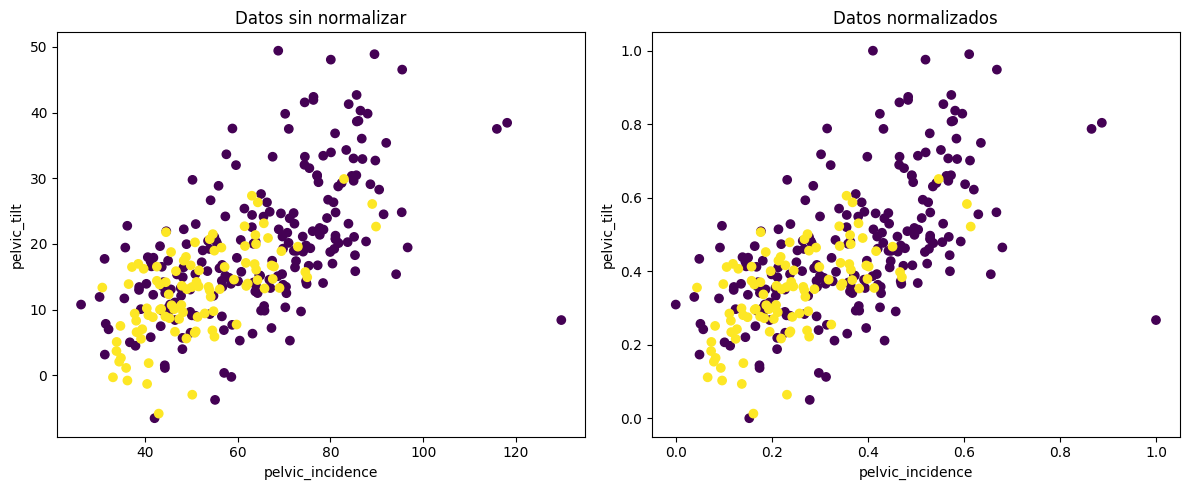

In [ ]:
feature_names = column_names[0:6]

# Visualizar los datos usando solo las dos primeras características antes de ser normalizados
plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Datos sin normalizar")
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])

# Visualizar los datos después de normalizarlos
plt.subplot(122)
plt.scatter(columna_normalized[:, 0], columna_normalized[:, 1], c=y)
plt.title("Datos normalizados")
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])

plt.tight_layout()
plt.show()

**¿Por qué es importante normalizar los datos antes de aplicar PCA?**

Porque PCA busca las direcciones de mayor **varianza**, y la varianza depende de la escala de cada variable. Si no normalizo, las variables con números más grandes o más dispersos (como la espondilolistesis, que llega a 418) se "comerían" la varianza y dominarían las componentes principales, solo por la unidad en la que están medidas y no porque sean más importantes. Con el MinMaxScaler todas quedan entre 0 y 1 y compiten en igualdad de condiciones. En el gráfico de arriba se ve que la forma de los datos es la misma, solo cambian los ejes.

**PCA**

In [ ]:
from sklearn.decomposition import PCA

# Aplicar PCA
pca = PCA()
X_pca = pca.fit_transform(columna_normalized)

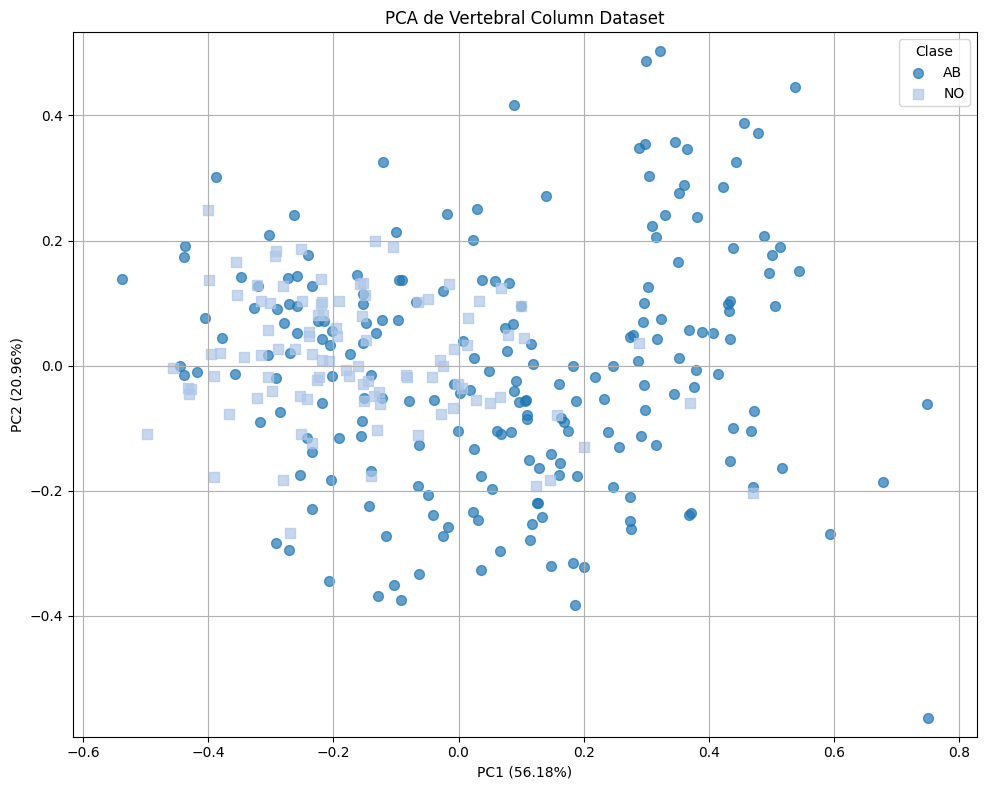

In [ ]:
# Etiquetas
clase_paciente = datos['clase'].values

# DataFrame con los resultados del PCA
pca_data = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
pca_data['clase'] = clase_paciente

# Colores y marcadores
cmap = plt.get_cmap('tab20')
markers = ['o', 's']

plt.figure(figsize=(10, 8))

for i, (tipo, grupo) in enumerate(pca_data.groupby('clase')):
    plt.scatter(grupo['PC1'], grupo['PC2'],
                color=cmap(i % 20), marker=markers[i % len(markers)],
                label=tipo, alpha=0.7, s=50)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('PCA de Vertebral Column Dataset')
plt.legend(title='Clase', loc='best')
plt.grid(True)
plt.axis('equal')
plt.tight_layout()
plt.show()

En el gráfico de PC1 vs PC2 se ve que los pacientes normales (NO) quedan bastante agrupados del lado izquierdo (PC1 negativo), mientras que los anormales (AB) están mucho más dispersos y se van hacia la derecha. Igual hay bastante superposición en la zona central, hay muchos AB metidos entre los NO, así que en 2D las clases no se separan del todo.

In [ ]:
# Crear un DataFrame con los resultados del PCA
pca_df = pd.DataFrame(data = {
    'standard_deviation': np.sqrt(pca.explained_variance_),
    'proportion_of_variance': pca.explained_variance_ratio_,
    'cumulative_proportion': np.cumsum(pca.explained_variance_ratio_)
})

# Añadir una columna para los componentes principales
pca_df.index = [f'PC{i}' for i in range(1, len(pca_df) + 1)]
pca_df.index.name = 'component'

print("Resumen de PCA:")
print(pca_df)
print("\n")

Resumen de PCA:
           standard_deviation  proportion_of_variance  cumulative_proportion
component                                                                   
PC1                  0.271034            5.618149e-01               0.561815
PC2                  0.165535            2.095684e-01               0.771383
PC3                  0.131830            1.329153e-01               0.904299
PC4                  0.092462            6.538458e-02               0.969683
PC5                  0.062961            3.031681e-02               1.000000
PC6                  0.000033            8.546456e-09               1.000000




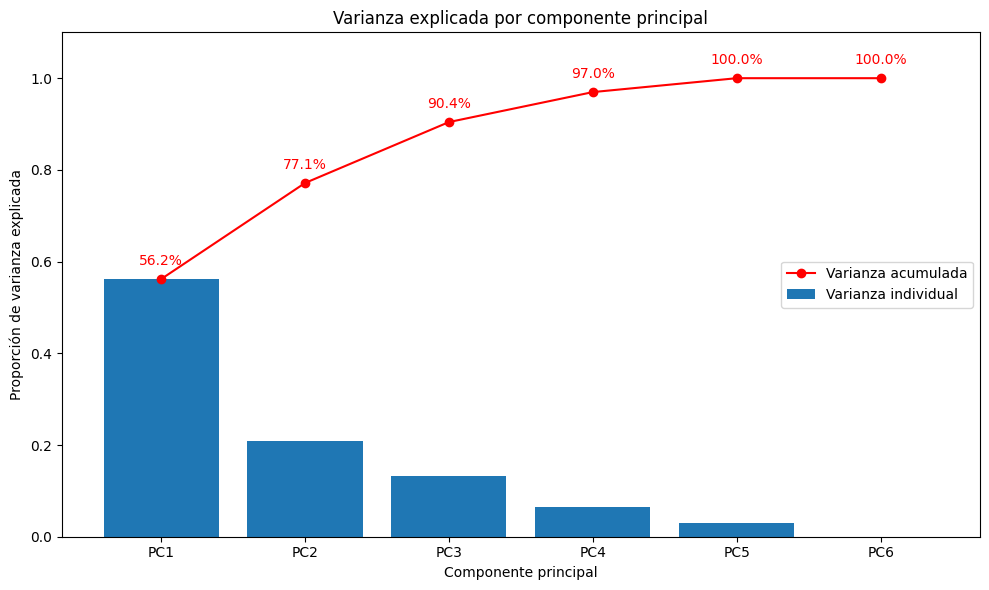

In [ ]:
var = pca.explained_variance_ratio_
acum = np.cumsum(var)
pcs = np.arange(1, len(var) + 1)

plt.figure(figsize=(10, 6))
plt.bar(pcs, var, label='Varianza individual')
plt.plot(pcs, acum, marker='o', color='red', label='Varianza acumulada')

# Etiquetar el % acumulado sobre cada punto
for pc, a in zip(pcs, acum):
    plt.text(pc, a + 0.03, f'{a:.1%}', ha='center', color='red')

plt.xticks(pcs, [f'PC{i}' for i in pcs])
plt.ylim(0, 1.1)
plt.xlabel('Componente principal')
plt.ylabel('Proporción de varianza explicada')
plt.title('Varianza explicada por componente principal')
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

**Verificar la cantidad de varianza que están explicando los primeros componentes principales (PC1 + PC2).**

- PC1 explica el **56,18 %** de la varianza.
- PC2 explica el **20,96 %**.
- Entre los dos explican el **77,14 %**.

Con dos componentes se captura más de tres cuartos de la información, así que el gráfico 2D es bastante representativo, aunque se pierde un poco más que en los ejemplos de clase (en Iris era más del 95 %). Con PC3 ya se llega al 90 %.

Algo que me llamó la atención es que **PC6 explica prácticamente 0 %** de la varianza (8,5e-09). Esto pasa porque la incidencia pélvica es exactamente la suma de la inclinación pélvica y la pendiente sacra (PI = PT + SS), entonces una de las 6 variables es combinación lineal de otras dos y en realidad los datos tienen solo 5 dimensiones "reales".

In [ ]:
# Obtener los vectores de carga (loadings)
loadings = pca.components_.T

# Crear un DataFrame con los loadings
loadings_df = pd.DataFrame(loadings, columns=[f'PC{i}' for i in range(1, len(loadings[0]) + 1)],
                           index=column_names[0:6])

print("Vectores de carga (Loadings):")
print(loadings_df)
print("\n")

Vectores de carga (Loadings):
                               PC1       PC2       PC3       PC4       PC5  \
pelvic_incidence          0.591618 -0.100082 -0.032411 -0.408923 -0.226190   
pelvic_tilt               0.467093  0.670434 -0.455731  0.015968 -0.042366   
lumbar_lordosis_angle     0.515062 -0.080138  0.436250  0.733444 -0.005832   
sacral_slope              0.325660 -0.443336  0.204986 -0.400610 -0.195023   
pelvic_radius            -0.115824  0.580957  0.737899 -0.295136 -0.132189   
degree_spondylolisthesis  0.216917 -0.004624  0.120129 -0.216780  0.944193   

                               PC6  
pelvic_incidence         -0.648491  
pelvic_tilt               0.350145  
lumbar_lordosis_angle    -0.000002  
sacral_slope              0.675912  
pelvic_radius             0.000007  
degree_spondylolisthesis -0.000030  




**En base a los vectores cargas, ¿cuál es la feature más relevante para PC1? ¿Y para PC2?**

- **PC1:** la de mayor carga (en valor absoluto) es **`pelvic_incidence` (0,59)**, seguida de `lumbar_lordosis_angle` (0,52) y `pelvic_tilt` (0,47). Todas con el mismo signo, así que PC1 se podría interpretar como algo así como "cuánto ángulo tiene la pelvis y la columna lumbar" en general.
- **PC2:** la más relevante es **`pelvic_tilt` (0,67)**, seguida de `pelvic_radius` (0,58) y `sacral_slope` (-0,44). La pendiente sacra tiene signo opuesto, entonces PC2 separa a los pacientes con la pelvis más inclinada hacia atrás de los que tienen el sacro más inclinado.

`degree_spondylolisthesis` no pesa mucho ni en PC1 (0,22) ni en PC2 (casi 0), recién aparece fuerte en PC5 (0,94).

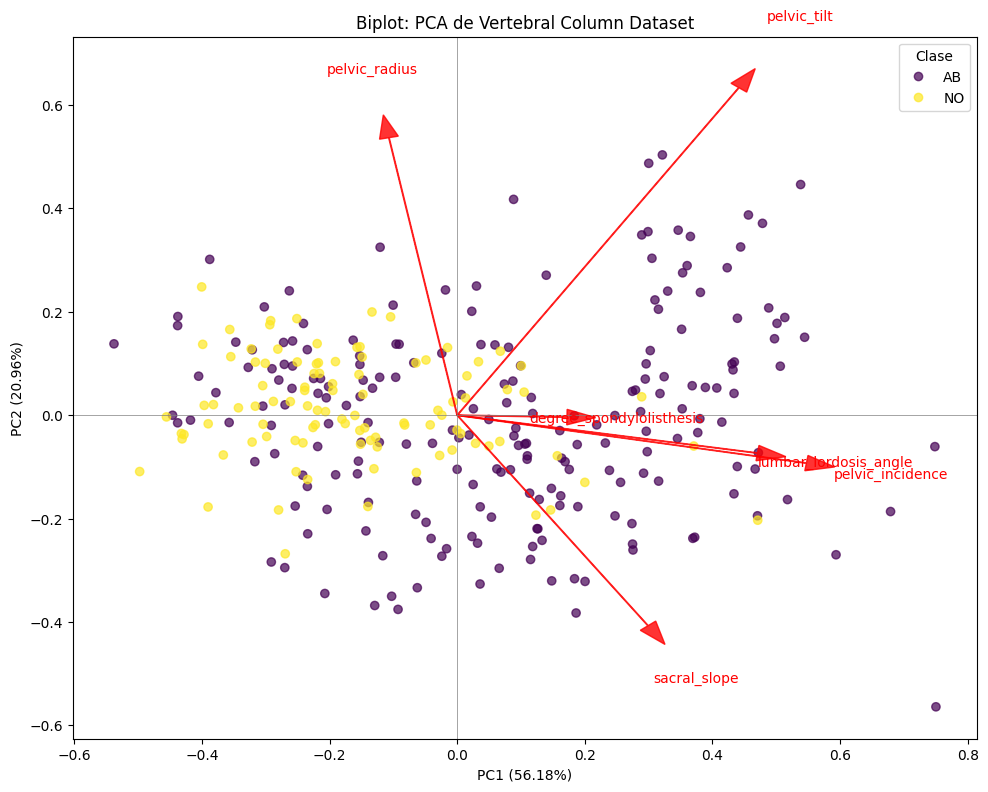

In [ ]:
plt.figure(figsize=(10, 8))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', alpha=0.7)

for i, (lx, ly) in enumerate(zip(loadings[:, 0], loadings[:, 1])):
    plt.arrow(0, 0, lx, ly, color='r', alpha=0.8,
              head_width=0.03, length_includes_head=True)
    plt.text(lx * 1.15, ly * 1.15, column_names[i],
             color='r', ha='center', va='center')

plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.legend(sc.legend_elements()[0], label_encoder.classes_, title='Clase')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('Biplot: PCA de Vertebral Column Dataset')
plt.tight_layout()
plt.show()

**En base al biplot, ¿cuál es la feature más relevante para PC1? ¿Y para PC2?**

En el biplot coincide con lo de las cargas:
- Para **PC1** la flecha más larga en la dirección horizontal es la de **`pelvic_incidence`**, casi pegada a la de `lumbar_lordosis_angle`. Que estén tan juntas quiere decir que están muy correlacionadas.
- Para **PC2** la flecha más vertical y larga es la de **`pelvic_tilt`**, y muy cerca está `pelvic_radius`. `sacral_slope` apunta para abajo (signo negativo en PC2).

También se ve que la flecha de `degree_spondylolisthesis` es muy cortita, porque tras normalizar casi todos los valores quedaron cerca de 0 (por culpa del outlier de 418) y entonces aporta poca varianza. Además, los pacientes AB que están más a la derecha van en la misma dirección que las flechas de incidencia pélvica y lordosis, o sea que los anormales tienden a tener ángulos más grandes.

Es curioso que la variable que menos pesa en PCA es la que después resulta más importante para clasificar. Esto tiene sentido porque PCA busca varianza, no separación entre clases.

## **5- Machine learning**

### **Random forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

In [ ]:
# Verificar que en X sigan las features y en y las etiquetas
print(X)
print(y)

[[ 63.03  22.55  39.61  40.48  98.67  -0.25]
 [ 39.06  10.06  25.02  29.   114.41   4.56]
 [ 68.83  22.22  50.09  46.61 105.99  -3.53]
 ...
 [ 61.45  22.69  46.17  38.75 125.67  -2.71]
 [ 45.25   8.69  41.58  36.56 118.55   0.21]
 [ 33.84   5.07  36.64  28.77 123.95  -0.2 ]]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [ ]:
# Definir y entrenar el modelo Random Forest con OOB (Out-Of-Bag)
rf_model = RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)
rf_model.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metri

In [ ]:
# Imprimir un resumen del modelo
print("Resumen del modelo Random Forest:")
print(f"Número de árboles: {rf_model.n_estimators}")
print(f"Precisión OOB: {rf_model.oob_score_:.4f}")
print(f"Número de características: {rf_model.n_features_in_}")
print(f"Clases: {rf_model.classes_}")

Resumen del modelo Random Forest:
Número de árboles: 1000
Precisión OOB: 0.8516
Número de características: 6
Clases: [0 1]


**Obtener e interpretar la precisión OOB.**

La precisión OOB dio **0,8516**, o sea que el modelo clasifica bien aproximadamente el **85 %** de los pacientes que no vio durante el entrenamiento de cada árbol. Está bastante por encima del 68 % que daría decir "AB" para todos, así que el modelo sí está aprendiendo algo. Las clases quedan como [0 1], que son AB y NO.

In [ ]:
# Obtener las predicciones OOB
oob_predictions = rf_model.oob_decision_function_

# Convertir probabilidades a etiquetas de clase (la clase con la probabilidad más alta)
oob_predicted_labels = rf_model.classes_[np.argmax(oob_predictions, axis=1)]

# Crear la matriz de confusión usando las etiquetas reales y las predicciones OOB
conf_matrix = confusion_matrix(y, oob_predicted_labels, labels=rf_model.classes_)

# Convertir la matriz de confusión a un DataFrame para un formato legible
conf_matrix_df = pd.DataFrame(conf_matrix, index=rf_model.classes_, columns=rf_model.classes_)

# Calcular el error de clase para cada clase
class_error = 1 - np.diag(conf_matrix) / np.sum(conf_matrix, axis=1)

# Imprimir la matriz de confusión con nombres de filas y columnas
print("Matriz de Confusión OOB con Nombres de Clases:")
print(conf_matrix_df)

# Imprimir el error de clase para cada clase
print("\nError de Clase (Class Error) por clase:")
for cls, error in zip(rf_model.classes_, class_error):
    print(f"Clase {cls}: Error de Clase {error:.4f}")

Matriz de Confusión OOB con Nombres de Clases:
     0   1
0  189  21
1   25  75

Error de Clase (Class Error) por clase:
Clase 0: Error de Clase 0.1000
Clase 1: Error de Clase 0.2500


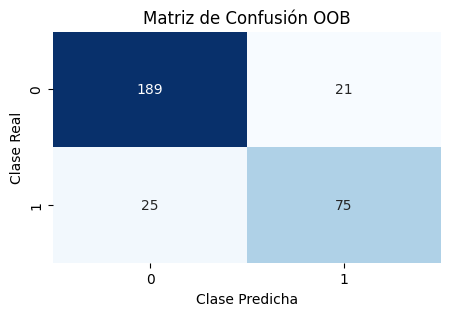

In [ ]:
import seaborn as sns

# Visualizar la matriz de confusión usando un heatmap
plt.figure(figsize=(5, 3))
sns.heatmap(conf_matrix_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusión OOB')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

En la matriz de confusión OOB (recordar que 0 = AB y 1 = NO):
- De los 210 pacientes AB, **189** se clasificaron bien y 21 se confundieron con NO (error del 10 %).
- De los 100 pacientes NO, **75** se clasificaron bien y 25 se confundieron con AB (error del 25 %).

O sea que al modelo le cuesta más reconocer a los pacientes sanos. Supongo que es por el desbalance (hay el doble de AB) y porque los pacientes con hernia de disco tienen medidas parecidas a las de los normales, como se veía en el PCA donde había muchos AB mezclados con los NO.

In [ ]:
# Importancia de las características
feature_importance = rf_model.feature_importances_
for i, importance in enumerate(feature_importance):
    print(f"Importancia de la característica {i+1}: {importance:.4f}")

Importancia de la característica 1: 0.1225
Importancia de la característica 2: 0.1186
Importancia de la característica 3: 0.1115
Importancia de la característica 4: 0.1193
Importancia de la característica 5: 0.1750
Importancia de la característica 6: 0.3531


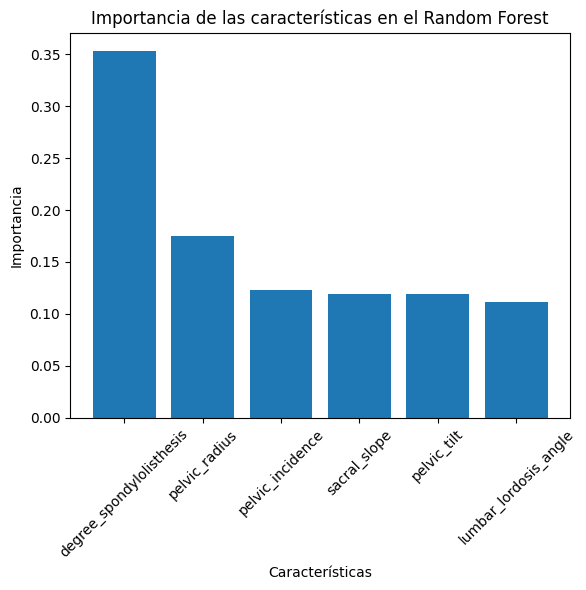

In [ ]:
# Obtener los nombres de las características
feature_names = column_names[0:6]  # Excluyo la columna 'clase'

# Ordenar las características por importancia en orden descendente
sorted_idx = np.argsort(feature_importance)[::-1]
sorted_feature_importance = feature_importance[sorted_idx]
sorted_feature_names = np.array(feature_names)[sorted_idx]

# Crear el gráfico de barras
plt.figure(figsize=(6, 6))
plt.bar(range(len(sorted_feature_importance)), sorted_feature_importance, align='center')
plt.xticks(range(len(sorted_feature_names)), sorted_feature_names, rotation=45)
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.title('Importancia de las características en el Random Forest')
plt.tight_layout()
plt.show()

**Ordenar las características por importancia.**

1. `degree_spondylolisthesis`: 0,353
2. `pelvic_radius`: 0,175
3. `pelvic_incidence`: 0,123
4. `sacral_slope`: 0,119
5. `pelvic_tilt`: 0,119
6. `lumbar_lordosis_angle`: 0,112

La más importante, por lejos, es el **grado de espondilolistesis**, que tiene sentido clínicamente porque si una vértebra está desplazada ya es directamente una patología. Después está el radio pélvico y el resto quedan todas muy parejas.

**¿Qué ventajas tiene la evaluación OOB? ¿En qué se diferencia de evaluar el modelo con un conjunto de test independiente?**

Cada árbol del Random Forest se entrena con una muestra bootstrap (al azar y con reemplazo), y aproximadamente **un tercio de los datos queda afuera** de cada muestra. Esos datos son los out-of-bag. Para estimar el error, cada paciente se predice solamente con los árboles que no lo usaron para entrenar.

Ventajas:
- **No hace falta separar un conjunto de test**, entonces se pueden usar todos los datos para entrenar. Esto está bueno en un dataset chico como el mío (310 pacientes).
- La estimación sale "gratis" del mismo entrenamiento, no hay que hacer nada extra.
- No depende de cómo cayó una partición train/test particular.

La diferencia con un test independiente es que en el test se aparta un grupo de datos que el modelo completo nunca ve, y se lo evalúa una sola vez con todos los árboles. En OOB cada dato se evalúa con un sub-ensamble distinto (solo con los árboles que no lo vieron), así que no es exactamente el mismo modelo final, pero en la práctica da una estimación muy parecida al error de test.

### **Árboles de decisión**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

In [ ]:
# dividir los datos en conjuntos de entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

In [ ]:
# Obtener las frecuencias de clases en el conjunto total de entrenamiento
clases_train = pd.Series(y_train).value_counts()

print(clases_train)
# Calcular el total de frecuencias
total_frecuencias = clases_train.sum()
print(f'Total {total_frecuencias}')

0    147
1     70
Name: count, dtype: int64
Total 217


In [ ]:
# Obtener las frecuencias de clases en el conjunto total de test
clases_test = pd.Series(y_test).value_counts()
print(clases_test)
# Calcular el total de frecuencias
total_frecuencias = clases_test.sum()
print(f'Total {total_frecuencias}')

0    63
1    30
Name: count, dtype: int64
Total 93


In [ ]:
# definir y entrenar el modelo
clf = DecisionTreeClassifier(criterion="entropy", min_impurity_decrease=0.03, random_state=0, min_samples_leaf=5)
clf.fit(x_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [ ]:
# predecir las etiquetas para los datos de prueba y calcular la precisión del modelo
y_pred = clf.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)

# imprimir la precisión del modelo
print("Precisión del modelo: {:.2f}".format(accuracy))

Precisión del modelo: 0.81


In [ ]:
# Imprimir información sobre el árbol
print(f'Profundidad del árbol: {clf.get_depth()}')
print(f'Número de hojas: {clf.get_n_leaves()}')

Profundidad del árbol: 5
Número de hojas: 7


In [ ]:
# Imprimir las características más importantes ordenadas
importances = clf.feature_importances_
sorted_indices = np.argsort(importances)[::-1] # Ordena los índices en orden descendente

print('Variables más importantes ordenadas:')
for idx in sorted_indices:
    feature_name = datos.columns[idx]
    importance = importances[idx]
    print(f'{feature_name}: {importance}')

Variables más importantes ordenadas:
degree_spondylolisthesis: 0.6719989552180503
pelvic_radius: 0.13918490058561392
sacral_slope: 0.13746796298895603
pelvic_tilt: 0.0513481812073797
lumbar_lordosis_angle: 0.0
pelvic_incidence: 0.0


Usé la partición 70/30 con `random_state=0` (217 pacientes para entrenar y 93 para test) y los mismos hiperparámetros de la práctica: criterio de entropía, `min_impurity_decrease=0.03` y `min_samples_leaf=5`.

- **Precisión del modelo:** 0,81
- **Profundidad del árbol:** 5
- **Número de hojas:** 7

**Las características más importantes, ¿coinciden con lo observado en Random Forest?**

Sí, en parte. En los dos modelos la más importante es **`degree_spondylolisthesis`** y la segunda es **`pelvic_radius`**. La diferencia es que en el árbol la espondilolistesis acapara mucho más (0,67) y hay dos variables con importancia 0 (`lumbar_lordosis_angle` y `pelvic_incidence`), mientras que en el Random Forest todas tienen algo de importancia. Esto es porque el Random Forest elige variables al azar en cada nodo, entonces cuando la espondilolistesis no está disponible tiene que usar otras y la importancia se reparte más. Que `pelvic_incidence` quede en 0 en el árbol puede ser porque su información ya está en `pelvic_tilt` y `sacral_slope`, que sí aparecen.

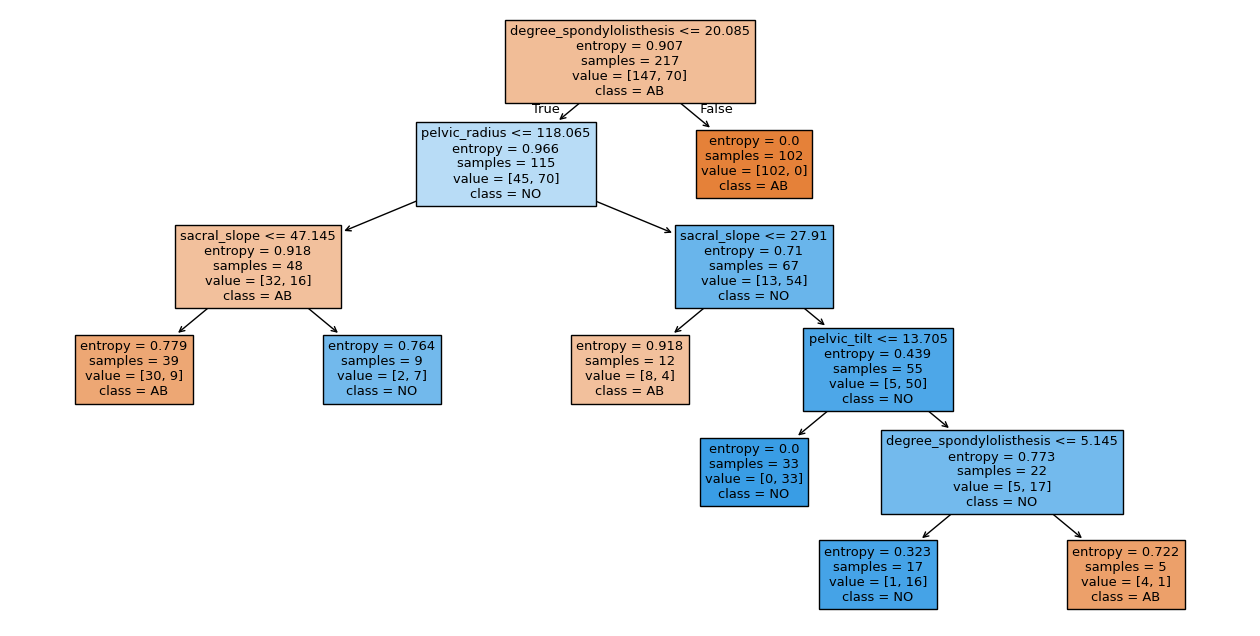

In [ ]:
plt.figure(figsize=(16, 8))
plot_tree(clf, filled=True, feature_names=datos.columns[0:6], class_names=[str(cls) for cls in label_encoder.classes_])
plt.savefig('decision_tree.pdf', format='pdf')  # Guarda el árbol en formato PDF
plt.show()  # Muestra el árbol en pantalla

La primera división es `degree_spondylolisthesis <= 20,085`. Todos los pacientes con más de 20 de espondilolistesis (102) van directo a AB sin ningún error, es la hoja más pura del árbol. Del otro lado quedan mezclados los normales con los anormales de espondilolistesis baja (los de hernia de disco, supongo), y para separarlos el árbol usa el radio pélvico, la pendiente sacra y la inclinación pélvica. Por ejemplo, con radio pélvico mayor a 118, pendiente sacra mayor a 27,9 e inclinación pélvica menor a 13,7, los 33 pacientes son NO.

### **Optativo: SVM**

También probé SVM con el código de la práctica. Usé la misma partición que en deep learning (80 % train+val y 20 % test, y del 80 % otro 80/20 para validación, con `random_state=42`), o sea 198 pacientes para entrenar, 50 para validar y 62 para test. La validación la uso para elegir el mejor valor de C, probando 11 valores entre 0,00001 y 100000, y después evalúo el modelo final en test. Igual que en la práctica, usé los datos sin normalizar.

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
# Separar datos para entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=42)

# Subdividir el conjunto de entrenamiento en train y val
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, train_size=0.8, test_size=0.2, random_state=42)

print("Tamaño del conjunto de entrenamiento:", len(X_train))
print("Tamaño del conjunto de validación:", len(X_val))
print("Tamaño del conjunto de prueba:", len(X_test))

Tamaño del conjunto de entrenamiento: 198
Tamaño del conjunto de validación: 50
Tamaño del conjunto de prueba: 62


In [ ]:
# Valores de C a evaluar
valores_C = np.logspace(-5, 5, num=11)

In [ ]:
valores_C

array([1.e-05, 1.e-04, 1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02,
       1.e+03, 1.e+04, 1.e+05])

Con kernel radial:

Mejor valor de C: 1.0
Precisión máxima: 0.82
Error mínimo en validación: 18.0%


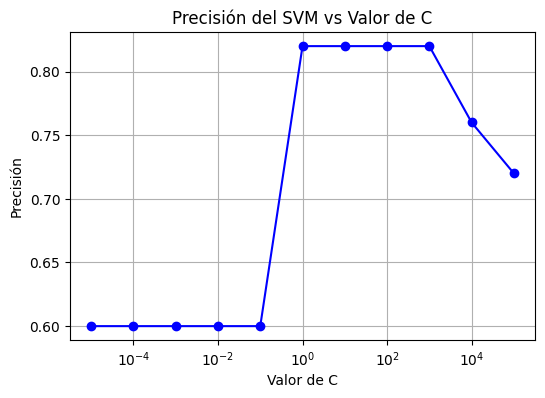


Resultados en el conjunto de prueba:
Precisión en test: 0.8548387096774194
Error en test: 14.52%

Matriz de Confusión:
[[40  4]
 [ 5 13]]

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.89      0.91      0.90        44
           1       0.76      0.72      0.74        18

    accuracy                           0.85        62
   macro avg       0.83      0.82      0.82        62
weighted avg       0.85      0.85      0.85        62



In [ ]:
# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:
    # Entrenar el modelo SVM con el valor actual de C
    modelo_svm = SVC(kernel='rbf', C=C)
    modelo_svm.fit(X_train, y_train)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_final = SVC(kernel='rbf', C=mejor_C)
modelo_svm_final.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_final.predict(X_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_test = accuracy_score(y_test, predicciones_test)
error_test = 1 - precision_test
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Precisión en test: {precision_test}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión
matriz_confusion = confusion_matrix(y_test, predicciones_test)
reporte_clasificacion = classification_report(y_test, predicciones_test)

print("\nMatriz de Confusión:")
print(matriz_confusion)
print("\nReporte de Clasificación:")
print(reporte_clasificacion)

**Kernel radial:** con C muy chicos (de 0,00001 a 0,1) la precisión en validación se queda en 0,60, que es justo la proporción de AB en el conjunto de validación (30 de 50). O sea que con C tan chico el modelo predice todo como AB. A partir de C = 1 sube a 0,82 y con C muy grandes vuelve a bajar un poco. El mejor fue **C = 1** y en test dio una precisión de **0,85** (error de 14,5 %). En la matriz de confusión se equivocó en 4 de 44 AB y en 5 de 18 NO.

Con kernel Polinomial:

Mejor valor de C: 0.1
Precisión máxima: 0.86
Error mínimo en validación: 14.0%


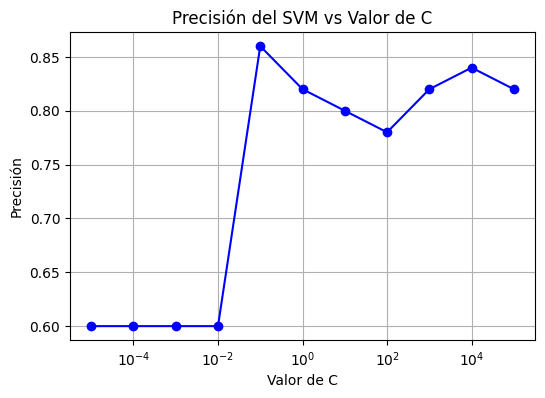


Resultados en el conjunto de prueba:
Precisión en test: 0.8709677419354839
Error en test: 12.9%

Matriz de Confusión:
[[42  2]
 [ 6 12]]

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.88      0.95      0.91        44
           1       0.86      0.67      0.75        18

    accuracy                           0.87        62
   macro avg       0.87      0.81      0.83        62
weighted avg       0.87      0.87      0.87        62



In [ ]:
# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:
    # Entrenar el modelo SVM con el valor actual de C
    modelo_svm = SVC(kernel='poly', C=C)
    modelo_svm.fit(X_train, y_train)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_final = SVC(kernel='poly', C=mejor_C)
modelo_svm_final.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_final.predict(X_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_test = accuracy_score(y_test, predicciones_test)
error_test = 1 - precision_test
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Precisión en test: {precision_test}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión
matriz_confusion = confusion_matrix(y_test, predicciones_test)
reporte_clasificacion = classification_report(y_test, predicciones_test)

print("\nMatriz de Confusión:")
print(matriz_confusion)
print("\nReporte de Clasificación:")
print(reporte_clasificacion)

**Kernel polinomial:** pasa lo mismo con los C chicos (0,60), pero acá el mejor fue **C = 0,1** con 0,86 en validación, y en test dio **0,87** (error de 12,9 %), que es el mejor resultado en test de todos los modelos. Se equivocó en 2 de 44 AB y en 6 de 18 NO, así que de nuevo la clase normal es la más difícil.

Igual hay que tener cuidado porque el conjunto de validación es muy chico (50 pacientes), entonces una diferencia de un solo paciente ya mueve la precisión 0,02, y el C que se elige puede cambiar bastante con otra partición.

### **Optativo: Deep learning**

Como parte optativa probé la red neuronal de la práctica de deep learning, con la misma arquitectura (capas de 256, 128 y 64 neuronas con BatchNormalization y Dropout de 0,5). Lo único que cambié es la capa de salida, que ahora tiene **2 neuronas** porque tengo 2 clases. Usé los datos sin normalizar (X), igual que en la práctica, y la partición 80/20 y después otra vez 80/20 para validación.

In [ ]:
from sklearn.model_selection import train_test_split

# Separar datos para entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=42)

# Subdividir el conjunto de entrenamiento en train y val
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, train_size=0.8, test_size=0.2, random_state=42)

print("Tamaño del conjunto de entrenamiento:", len(X_train))
print("Tamaño del conjunto de validación:", len(X_val))
print("Tamaño del conjunto de prueba:", len(X_test))

Tamaño del conjunto de entrenamiento: 198
Tamaño del conjunto de validación: 50
Tamaño del conjunto de prueba: 62


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Definir la red neuronal
model = models.Sequential()
model.add(layers.Dense(256, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(128, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dense(2, activation='softmax'))  # 2 clases: AB y NO

I0000 00:00:1793032036.145800    4033 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793032037.900479    4033 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [ ]:
# Compilar el modelo
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

In [ ]:
# Definir hiperparámetros
epocas = 30
batch_size = 32

Epoch 1/30


1/7 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.6562 - loss: 0.6935

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.6515 - loss: 0.7952 - val_accuracy: 0.7600 - val_loss: 0.8505


Epoch 2/30


1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8438 - loss: 0.4431

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7121 - loss: 0.6821 - val_accuracy: 0.7800 - val_loss: 0.9006


... (80 outputs left out)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8333 - loss: 0.3230 - val_accuracy: 0.8000 - val_loss: 0.5000


Epoch 30/30


1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8125 - loss: 0.5024

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8586 - loss: 0.3678 - val_accuracy: 0.8000 - val_loss: 0.4921


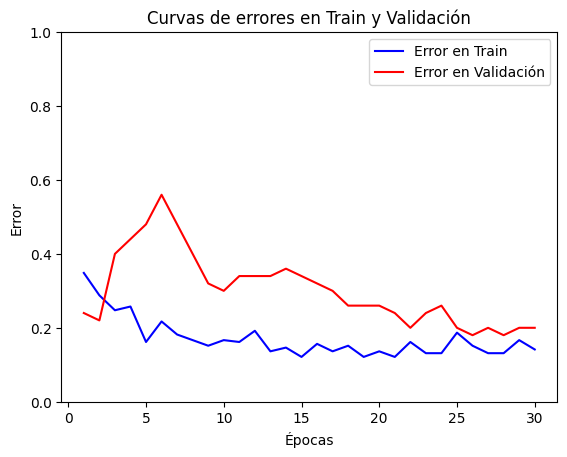

In [ ]:
# Entrenar el modelo y almacenar el historial
history = model.fit(X_train, y_train, epochs=epocas, batch_size=batch_size, validation_data=(X_val, y_val))

# Graficar error en función de las épocas
# Obtener los valores de accuracy y val_accuracy
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

# Obtener las curvas de error en train y validación
Error_train = [1 - acc for acc in train_accuracy]
Error_val = [1 - acc for acc in val_accuracy]

# Curvas de error en train y validación
epochs = range(1, len(train_accuracy) + 1)
plt.plot(epochs, Error_train, 'b', label='Error en Train')
plt.plot(epochs, Error_val, 'r', label='Error en Validación')
plt.title('Curvas de errores en Train y Validación')
plt.xlabel('Épocas')
plt.ylabel('Error')
plt.ylim([0, 1])
plt.legend()
plt.show()

In [ ]:
# Evaluar el modelo con los datos de test
test_loss, test_accuracy = model.evaluate(X_test, y_test)

# Imprimir el resultado
print(f'\nPérdida en Test: {test_loss}')
print(f'Precisión en Test: {test_accuracy}')

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8438 - loss: 0.4403

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8387 - loss: 0.4980



Pérdida en Test: 0.49796316027641296
Precisión en Test: 0.8387096524238586


La red llegó a una precisión en test de **0,84** (0,8387 en la corrida que quedó guardada). Hay que tener en cuenta que el test es muy chico (62 pacientes) y que cada vez que se corre da un poco distinto porque los pesos iniciales son aleatorios. En otras corridas que hice me dio entre 0,82 y 0,85.

En las curvas, el error de train baja bastante parejo y queda entre 0,12 y 0,2. El de validación en cambio sube mucho en las primeras épocas (llega a 0,56 en la época 6) y después va bajando hasta quedar en 0,2 al final. Creo que ese pico del principio es porque los datos no están normalizados y la BatchNormalization tarda en ajustarse. Al final las dos curvas quedan cerca, así que no parece haber un sobreajuste fuerte (el Dropout ayuda en eso).

### **Tabla comparativa**

| Modelo | Cómo se evaluó | Precisión |
|---|---|---|
| Random Forest (1000 árboles) | OOB (310 pacientes) | 0,85 |
| Árbol de decisión | Test 30 % (93 pacientes) | 0,81 |
| SVM kernel radial (C = 1) | Test 20 % (62 pacientes) | 0,85 |
| SVM kernel polinomial (C = 0,1) | Test 20 % (62 pacientes) | **0,87** |
| Red neuronal (deep learning) | Test 20 % (62 pacientes) | 0,84 (varía entre corridas) |
| Referencia: decir "AB" a todos | | 0,68 |

El que mejor dio en números fue el **SVM con kernel polinomial**, pero las diferencias son muy chicas: entre 0,84 y 0,87 hay solo 2 pacientes de diferencia en un test de 62. Además no todos se evaluaron con los mismos datos, así que no es una comparación exacta. Yo me quedaría con el **Random Forest** porque su precisión OOB usa los 310 pacientes (es más confiable que un test de 62), siempre da lo mismo con `random_state=0` y además te dice qué variables importan. El único que quedó claramente por debajo es el árbol de decisión.

## **Conclusiones**

Con las 6 medidas biomecánicas de la radiografía se puede distinguir bastante bien a un paciente con la columna normal de uno con patología. Todos los modelos superaron el 68 % que da la clase mayoritaria y quedaron entre 81 % y 87 %. El Random Forest, los dos SVM y la red neuronal dieron resultados muy parecidos (entre 84 % y 87 %), y el árbol de decisión fue el más bajo (81 %).

Del PCA saqué que con PC1 y PC2 se explica el 77 % de la varianza y que las variables que más pesan son las de ángulos pélvicos (incidencia pélvica, inclinación pélvica y lordosis). También que en 2D los normales quedan agrupados pero muchos anormales se mezclan con ellos, así que no se separan del todo.

Lo más interesante fue que la variable más importante para clasificar (el grado de espondilolistesis) es una de las que menos aporta en PCA. Esto muestra que PCA busca las direcciones de mayor varianza y no necesariamente las que mejor separan las clases.

En todos los modelos lo más difícil fue reconocer a los pacientes **normales**, que se confunden con los de hernia de disco porque estos tienen la espondilolistesis baja, igual que los sanos. Esto se suma a que hay el doble de anormales que de normales.